
# AURORA cfDNA Regional Fragmentation Analysis  
## Step 5 Notebook — Genomic and regulatory enrichment of sample-centered TFx-associated bins

This notebook builds on Step 4.

### Main purpose

Step 5 asks whether the **sample-centered tumor-fraction-associated regional fragmentation bins** are enriched in specific genomic or regulatory contexts.

### Primary foreground

```text
Step 4 primary sample-centered TFx-associated bins
```

### Correct background

```text
Step 3 sample-centered bins (top 5000 variable bin) tested in the robust bin-level screen
```

This is important because Step 3 tested only selected robust variable bins, not the whole genome.

### Main analyses

1. Create enrichment foreground/background sets  
2. Test enrichment in Step 2 significant chromosome arms  
3. Test enrichment by chromosome arm and cytoband  
4. Test enrichment against GENCODE-derived genomic features  
   - gene bodies  
   - promoters  
   - exons  
   - CDS  
   - UTRs  
5. Run direction-specific enrichment  
   - positive TFx coefficient bins  
   - negative TFx coefficient bins  
6. Generate enrichment tables and plots  

### Key idea

This step does **not** rerun the regional-fragmentation model.  
It asks where the significant bins are located relative to genomic features and whether that localization is more than expected from the tested-bin background.


In [2]:

# ============================================================
# STEP 1: Setup paths, parameters, imports, and helper functions
# ============================================================

from pathlib import Path
import gzip
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from statsmodels.stats.multitest import multipletests

try:
    from scipy.stats import fisher_exact
    SCIPY_AVAILABLE = True
except Exception as e:
    SCIPY_AVAILABLE = False
    print("WARNING: scipy.stats.fisher_exact is not available.")
    print("Install scipy or use an environment with scipy.")
    print(e)

warnings.filterwarnings("ignore", category=FutureWarning)

print("Step 5 notebook started:", time.ctime())

# -------------------------
# Project paths
# -------------------------

OUT_DIR = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/"
    "Fragmentation_analysis/Regional_Fragment_analysis/Result"
)

# IMPORTANT: updated Step 3 folder names provided by Rahul.
STEP3_TABLE_DIR = OUT_DIR / "Step3_bin_level_screen_tables"
STEP3_PLOT_DIR = OUT_DIR / "Step3_bin_level_screen_plots"

STEP4_TABLE_DIR = OUT_DIR / "Step4_biological_interpretation_tables"
STEP4_BED_DIR = OUT_DIR / "Step4_biological_interpretation_BED"

STEP5_TABLE_DIR = OUT_DIR / "Step5_enrichment_analysis_tables"
STEP5_PLOT_DIR = OUT_DIR / "Step5_enrichment_analysis_plots"
STEP5_BED_DIR = OUT_DIR / "Step5_enrichment_analysis_BED"

for d in [STEP5_TABLE_DIR, STEP5_PLOT_DIR, STEP5_BED_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# -------------------------
# Genome annotation
# -------------------------

GTF_FILE = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/Reference_genome/Human/gencode.v47.annotation.gtf"
)

# Optional:
# If you have a directory containing external BED annotation files
# such as ENCODE TFBS, ATAC, DNase, ChromHMM, H3K27ac, etc.,
# put that folder path here.
#
# Example:
# CUSTOM_BED_ANNOTATION_DIR = Path("/path/to/regulatory_annotation_beds")
#
# Leave as None to skip custom BED enrichment.
CUSTOM_BED_ANNOTATION_DIR = None

# -------------------------
# Input files from prior steps
# -------------------------

STEP4_PRIMARY_FILE = STEP4_TABLE_DIR / "04_primary_sample_centered_TFx_significant_bins.csv"
STEP4_PRIMARY_WITH_STEP2_FILE = STEP4_TABLE_DIR / "04_primary_sample_centered_TFx_significant_bins_with_step2_arm_overlap.csv"

STEP4_POSITIVE_FILE = STEP4_TABLE_DIR / "04_primary_sample_centered_TFx_positive_bins.csv"
STEP4_NEGATIVE_FILE = STEP4_TABLE_DIR / "04_primary_sample_centered_TFx_negative_bins.csv"

STEP4_STEP2_ARMS_FILE = STEP4_TABLE_DIR / "04_step2_sample_centered_significant_arms.csv"

# Step 3 selected/tested sample-centered bins.
# Main expected file from Step 3:
STEP3_BACKGROUND_FILE_CANDIDATES = [
    STEP3_TABLE_DIR / "03_selected_top_robust_variable_bins_sample_centered.csv",
    STEP3_TABLE_DIR / "03_selected_top_variable_bins_sample_centered.csv",
    STEP3_TABLE_DIR / "03_primary_model_results_sample_centered_robust_selected_bins.csv",
    STEP3_TABLE_DIR / "03_bin_level_model_results_sample_centered_top_variable_bins.csv",
]

# If needed for coordinates.
BIN_ANNOT_FILE = OUT_DIR / "Step1_QC_tables" / "01_bin_annotation_with_cytoband_chrom_arm.csv"

# -------------------------
# Parameters
# -------------------------

FDR_ALPHA = 0.05
PROMOTER_UPSTREAM_BP = 2000
PROMOTER_DOWNSTREAM_BP = 500

TOP_N_PLOT = 25

# For cytoband/arm enrichment, skip categories with extremely small background counts.
MIN_BACKGROUND_COUNT_FOR_ENRICHMENT = 5

print("\nUsing Step 3 table folder:", STEP3_TABLE_DIR)
print("Using Step 4 table folder:", STEP4_TABLE_DIR)
print("Step 5 table output:", STEP5_TABLE_DIR)
print("Step 5 plot output:", STEP5_PLOT_DIR)
print("GTF file:", GTF_FILE)


# -------------------------
# Helper functions
# -------------------------

def first_existing_file(candidates, required=True):
    for p in candidates:
        if Path(p).exists():
            print("Using file:", p)
            return Path(p)
    if required:
        raise FileNotFoundError(
            "None of the candidate files exist:\n" +
            "\n".join([str(p) for p in candidates])
        )
    return None


def chrom_sort_key(chrom):
    chrom = str(chrom).replace("chr", "")
    if chrom.endswith("p") or chrom.endswith("q"):
        chrom = chrom[:-1]
    if chrom.isdigit():
        return int(chrom)
    if chrom == "X":
        return 23
    if chrom == "Y":
        return 24
    if chrom in ["M", "MT"]:
        return 25
    return 999


def arm_sort_key(x):
    x = str(x)
    if x.endswith("p") or x.endswith("q"):
        return (chrom_sort_key(x[:-1]), x[-1])
    return (chrom_sort_key(x), "")


def coefficient_direction(coef):
    if pd.isna(coef):
        return "missing"
    if coef > 0:
        return "positive"
    if coef < 0:
        return "negative"
    return "zero"


def safe_neglog10(x):
    x = pd.to_numeric(x, errors="coerce")
    return -np.log10(np.clip(x, 1e-300, 1.0))


def add_fdr(df, p_col="p_value", q_col="q_value"):
    df[q_col] = np.nan
    ok = df[p_col].notna()
    if ok.sum() > 0:
        df.loc[ok, q_col] = multipletests(
            df.loc[ok, p_col].astype(float).values,
            method="fdr_bh",
        )[1]
    return df


def compute_fisher_enrichment(a, b, c, d):
    """
    2x2 table:
                     in annotation   not in annotation
    foreground            a                 b
    background            c                 d

    Background should exclude foreground when possible.
    """
    if not SCIPY_AVAILABLE:
        return np.nan, np.nan

    table = [[a, b], [c, d]]
    odds_ratio, p_value = fisher_exact(table, alternative="greater")
    return odds_ratio, p_value


def normalize_bin_table(df, bin_annot=None):
    """
    Ensure bin table has required columns:
    bin, chrom, start, end, chrom_arm, cytoband
    """
    out = df.copy()

    if "bin" not in out.columns:
        raise ValueError("Input table must contain a 'bin' column.")

    if bin_annot is not None:
        needed = ["chrom", "start", "end", "chrom_arm", "cytoband"]
        missing_needed = [c for c in needed if c not in out.columns]
        if len(missing_needed) > 0:
            annot_cols = ["bin"] + [c for c in needed if c in bin_annot.columns]
            out = out.merge(bin_annot[annot_cols], on="bin", how="left")

    for col in ["chrom", "start", "end"]:
        if col not in out.columns:
            raise ValueError(f"Column '{col}' is missing and required.")

    out["chrom"] = out["chrom"].astype(str)
    out["start"] = pd.to_numeric(out["start"], errors="coerce")
    out["end"] = pd.to_numeric(out["end"], errors="coerce")

    out = out.dropna(subset=["chrom", "start", "end"]).copy()
    out["start"] = out["start"].astype(int)
    out["end"] = out["end"].astype(int)

    if "chrom_arm" not in out.columns:
        out["chrom_arm"] = np.nan
    if "cytoband" not in out.columns:
        out["cytoband"] = np.nan

    return out


def parse_gtf_attributes(attr):
    d = {}
    if pd.isna(attr):
        return d
    parts = [x.strip() for x in str(attr).split(";") if x.strip()]
    for p in parts:
        if " " in p:
            key, val = p.split(" ", 1)
            d[key] = val.replace('"', '').strip()
    return d


def load_gtf(gtf_file):
    cols = [
        "chrom", "source", "feature", "start", "end",
        "score", "strand", "frame", "attribute"
    ]

    print("Loading GTF:", gtf_file)
    gtf = pd.read_csv(
        gtf_file,
        sep="\t",
        comment="#",
        names=cols,
        low_memory=False,
    )

    gtf["start"] = pd.to_numeric(gtf["start"], errors="coerce") - 1
    gtf["end"] = pd.to_numeric(gtf["end"], errors="coerce")
    gtf = gtf.dropna(subset=["chrom", "start", "end"]).copy()
    gtf["start"] = gtf["start"].astype(int)
    gtf["end"] = gtf["end"].astype(int)

    attrs = gtf["attribute"].apply(parse_gtf_attributes)
    gtf["gene_id"] = attrs.apply(lambda d: d.get("gene_id", ""))
    gtf["gene_name"] = attrs.apply(lambda d: d.get("gene_name", d.get("gene_id", "")))
    gtf["gene_type"] = attrs.apply(lambda d: d.get("gene_type", d.get("gene_biotype", "")))

    return gtf


def merge_intervals(intervals_df):
    """
    Merge intervals by chromosome.
    Input columns: chrom, start, end
    Returns dict: chrom -> list of (start, end)
    """
    merged = {}

    for chrom, sub in intervals_df.groupby("chrom"):
        sub = sub[["start", "end"]].dropna().copy()
        if sub.empty:
            merged[chrom] = []
            continue

        sub["start"] = sub["start"].astype(int)
        sub["end"] = sub["end"].astype(int)
        sub = sub.sort_values(["start", "end"])

        intervals = []
        cur_start = None
        cur_end = None

        for _, r in sub.iterrows():
            s, e = int(r["start"]), int(r["end"])
            if cur_start is None:
                cur_start, cur_end = s, e
            elif s <= cur_end:
                cur_end = max(cur_end, e)
            else:
                intervals.append((cur_start, cur_end))
                cur_start, cur_end = s, e

        if cur_start is not None:
            intervals.append((cur_start, cur_end))

        merged[chrom] = intervals

    return merged


def interval_overlaps_any(chrom, start, end, merged_dict):
    """
    Check if interval overlaps any merged interval on same chromosome.
    Uses binary-search-like scan with sorted intervals.
    """
    intervals = merged_dict.get(chrom, [])
    if len(intervals) == 0:
        return False

    # Simple binary search to find first interval with end >= start.
    lo, hi = 0, len(intervals) - 1
    idx = len(intervals)

    while lo <= hi:
        mid = (lo + hi) // 2
        if intervals[mid][1] >= start:
            idx = mid
            hi = mid - 1
        else:
            lo = mid + 1

    if idx == len(intervals):
        return False

    s, e = intervals[idx]
    return s <= end and e >= start


def mark_overlap(bin_df, merged_intervals, label):
    out = bin_df.copy()
    out[label] = [
        interval_overlaps_any(chrom, start, end, merged_intervals)
        for chrom, start, end in zip(out["chrom"], out["start"], out["end"])
    ]
    return out


def build_promoter_intervals(genes_df, upstream=2000, downstream=500):
    """
    Build promoter intervals from gene-level GTF rows.
    For + strand: TSS = start
    For - strand: TSS = end
    promoter = TSS-upstream to TSS+downstream for + strand
             = TSS-downstream to TSS+upstream for - strand
    """
    genes = genes_df.copy()

    plus = genes["strand"].eq("+")
    minus = genes["strand"].eq("-")

    tss = np.where(plus, genes["start"], genes["end"])

    prom_start = np.where(
        plus,
        tss - upstream,
        tss - downstream,
    )

    prom_end = np.where(
        plus,
        tss + downstream,
        tss + upstream,
    )

    promoter = pd.DataFrame({
        "chrom": genes["chrom"].astype(str),
        "start": np.maximum(prom_start, 0).astype(int),
        "end": np.maximum(prom_end, 1).astype(int),
    })

    promoter = promoter[promoter["end"] > promoter["start"]].copy()

    return promoter


def enrichment_for_annotation(fg_df, bg_df, feature_col, annotation_name, foreground_name):
    """
    Fisher enrichment of feature_col overlap in foreground vs background not in foreground.
    """
    fg_bins = set(fg_df["bin"].astype(str))
    bg_non_fg = bg_df[~bg_df["bin"].astype(str).isin(fg_bins)].copy()

    a = int(fg_df[feature_col].sum())
    b = int(fg_df.shape[0] - a)
    c = int(bg_non_fg[feature_col].sum())
    d = int(bg_non_fg.shape[0] - c)

    odds_ratio, p_value = compute_fisher_enrichment(a, b, c, d)

    fg_frac = a / fg_df.shape[0] if fg_df.shape[0] > 0 else np.nan
    bg_frac = c / bg_non_fg.shape[0] if bg_non_fg.shape[0] > 0 else np.nan

    return {
        "foreground": foreground_name,
        "annotation": annotation_name,
        "foreground_total": fg_df.shape[0],
        "foreground_overlap": a,
        "foreground_fraction": fg_frac,
        "background_total_excluding_foreground": bg_non_fg.shape[0],
        "background_overlap": c,
        "background_fraction": bg_frac,
        "odds_ratio": odds_ratio,
        "p_value": p_value,
    }


def category_enrichment(fg_df, bg_df, category_col, foreground_name, min_bg_count=5):
    """
    Enrichment for categorical groups such as chrom_arm or cytoband.
    """
    rows = []
    fg_bins = set(fg_df["bin"].astype(str))
    bg_non_fg = bg_df[~bg_df["bin"].astype(str).isin(fg_bins)].copy()

    categories = sorted(
        set(fg_df[category_col].dropna().astype(str)).union(
            set(bg_non_fg[category_col].dropna().astype(str))
        )
    )

    for cat in categories:
        a = int(fg_df[category_col].astype(str).eq(cat).sum())
        b = int(fg_df.shape[0] - a)
        c = int(bg_non_fg[category_col].astype(str).eq(cat).sum())
        d = int(bg_non_fg.shape[0] - c)

        if c + a < min_bg_count:
            continue

        odds_ratio, p_value = compute_fisher_enrichment(a, b, c, d)

        rows.append({
            "foreground": foreground_name,
            "category_type": category_col,
            "category": cat,
            "foreground_total": fg_df.shape[0],
            "foreground_count": a,
            "foreground_fraction": a / fg_df.shape[0] if fg_df.shape[0] > 0 else np.nan,
            "background_total_excluding_foreground": bg_non_fg.shape[0],
            "background_count": c,
            "background_fraction": c / bg_non_fg.shape[0] if bg_non_fg.shape[0] > 0 else np.nan,
            "odds_ratio": odds_ratio,
            "p_value": p_value,
        })

    out = pd.DataFrame(rows)
    if out.shape[0] > 0:
        out = add_fdr(out, "p_value", "q_value")
        out = out.sort_values(["q_value", "p_value"], na_position="last")
    return out


def write_bed(df, path, name_prefix):
    out = df.copy()
    out["name"] = [f"{name_prefix}_{i+1}_{b}" for i, b in enumerate(out["bin"].astype(str))]
    out["score"] = 0
    if "q_tumor_fraction_percent" in out.columns:
        out["score"] = np.clip(safe_neglog10(out["q_tumor_fraction_percent"]) * 100, 0, 1000).fillna(0).astype(int)
    out["strand"] = "."

    cols = ["chrom", "start", "end", "name", "score", "strand", "bin", "chrom_arm", "cytoband"]
    cols = [c for c in cols if c in out.columns]

    out[cols].to_csv(path, sep="\t", index=False, header=False)
    print("Saved BED:", path, "rows:", out.shape[0])


def plot_enrichment_bar(df, path, title, label_col="annotation", top_n=25):
    if df.empty:
        print("No enrichment results to plot:", title)
        return

    tmp = df.copy()
    tmp = tmp[tmp["p_value"].notna()].copy()
    if tmp.empty:
        print("No valid p-values to plot:", title)
        return

    tmp["minus_log10_q"] = safe_neglog10(tmp["q_value"])
    tmp = tmp.sort_values(["q_value", "odds_ratio"], ascending=[True, False]).head(top_n)
    tmp = tmp.iloc[::-1].copy()

    fig, ax = plt.subplots(figsize=(8, max(4, 0.35 * tmp.shape[0])))
    ax.barh(tmp[label_col].astype(str), tmp["minus_log10_q"])
    ax.axvline(-np.log10(FDR_ALPHA), linewidth=1, linestyle="--")
    ax.set_xlabel("-log10(FDR q-value)")
    ax.set_ylabel("")
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(path, dpi=300)
    plt.show()


def plot_fraction_comparison(df, path, title, label_col="annotation", top_n=25):
    if df.empty:
        print("No fraction comparison results to plot:", title)
        return

    tmp = df.copy()
    tmp = tmp.sort_values(["q_value", "odds_ratio"], ascending=[True, False]).head(top_n)
    tmp = tmp.iloc[::-1].copy()

    y = np.arange(tmp.shape[0])

    fig, ax = plt.subplots(figsize=(8, max(4, 0.35 * tmp.shape[0])))
    ax.barh(y - 0.18, tmp["foreground_fraction"], height=0.35, label="Foreground")
    ax.barh(y + 0.18, tmp["background_fraction"], height=0.35, label="Background")
    ax.set_yticks(y)
    ax.set_yticklabels(tmp[label_col].astype(str))
    ax.set_xlabel("Fraction overlapping annotation")
    ax.set_ylabel("")
    ax.set_title(title)
    ax.legend(frameon=False)
    fig.tight_layout()
    fig.savefig(path, dpi=300)
    plt.show()


def read_bed_intervals(path):
    """
    Read BED or BED.GZ. Uses first 3 columns only.
    """
    p = Path(path)
    opener = gzip.open if str(p).endswith(".gz") else open

    rows = []
    with opener(p, "rt") as fh:
        for line in fh:
            if not line.strip() or line.startswith("#"):
                continue
            parts = line.rstrip("\n").split("\t")
            if len(parts) < 3:
                continue
            try:
                rows.append((parts[0], int(float(parts[1])), int(float(parts[2]))))
            except Exception:
                continue

    return pd.DataFrame(rows, columns=["chrom", "start", "end"])


/ihome/alee/rak373/.local/lib/python3.11/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.4' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/ihome/alee/rak373/.local/lib/python3.11/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


Step 5 notebook started: Tue Jun 16 11:47:33 2026

Using Step 3 table folder: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Fragmentation_analysis/Regional_Fragment_analysis/Result/Step3_bin_level_screen_tables
Using Step 4 table folder: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Fragmentation_analysis/Regional_Fragment_analysis/Result/Step4_biological_interpretation_tables
Step 5 table output: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Fragmentation_analysis/Regional_Fragment_analysis/Result/Step5_enrichment_analysis_tables
Step 5 plot output: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Fragmentation_analysis/Regional_Fragment_analysis/Result/Step5_enrichment_analysis_plots
GTF file: /ix1/alee/LO_LAB/Personal/Rahul/Reference_genome/Human/gencode.v47.annotation.gtf


In [3]:

# ============================================================
# STEP 2: Load foreground and background bin sets
# ============================================================

if not GTF_FILE.exists():
    raise FileNotFoundError(f"GTF file not found: {GTF_FILE}")

if not BIN_ANNOT_FILE.exists():
    raise FileNotFoundError(f"Bin annotation file not found: {BIN_ANNOT_FILE}")

for p in [STEP4_PRIMARY_FILE, STEP4_POSITIVE_FILE, STEP4_NEGATIVE_FILE]:
    if not Path(p).exists():
        raise FileNotFoundError(f"Missing Step 4 file: {p}")

bin_annot = pd.read_csv(BIN_ANNOT_FILE)

# Primary foreground from Step 4.
primary = pd.read_csv(STEP4_PRIMARY_FILE)
positive = pd.read_csv(STEP4_POSITIVE_FILE)
negative = pd.read_csv(STEP4_NEGATIVE_FILE)

# Prefer Step4 file with Step2 overlap if present.
if STEP4_PRIMARY_WITH_STEP2_FILE.exists():
    primary_with_step2 = pd.read_csv(STEP4_PRIMARY_WITH_STEP2_FILE)
else:
    primary_with_step2 = primary.copy()

# Background from Step 3 selected/tested sample-centered bins.
background_file = first_existing_file(STEP3_BACKGROUND_FILE_CANDIDATES, required=True)
background = pd.read_csv(background_file)

# Normalize required coordinate columns.
primary = normalize_bin_table(primary, bin_annot=bin_annot)
positive = normalize_bin_table(positive, bin_annot=bin_annot)
negative = normalize_bin_table(negative, bin_annot=bin_annot)
primary_with_step2 = normalize_bin_table(primary_with_step2, bin_annot=bin_annot)
background = normalize_bin_table(background, bin_annot=bin_annot)

# Ensure unique bins.
primary = primary.drop_duplicates("bin").copy()
positive = positive.drop_duplicates("bin").copy()
negative = negative.drop_duplicates("bin").copy()
primary_with_step2 = primary_with_step2.drop_duplicates("bin").copy()
background = background.drop_duplicates("bin").copy()

# Check foreground is subset of background.
bg_bins = set(background["bin"].astype(str))
primary["in_background"] = primary["bin"].astype(str).isin(bg_bins)
positive["in_background"] = positive["bin"].astype(str).isin(bg_bins)
negative["in_background"] = negative["bin"].astype(str).isin(bg_bins)

print("Primary foreground bins:", primary.shape[0])
print("Positive TFx bins:", positive.shape[0])
print("Negative TFx bins:", negative.shape[0])
print("Background tested sample-centered bins:", background.shape[0])

print("\nForeground bins found in background:")
display(pd.DataFrame([
    {"set": "primary", "n_bins": primary.shape[0], "n_in_background": int(primary["in_background"].sum())},
    {"set": "positive", "n_bins": positive.shape[0], "n_in_background": int(positive["in_background"].sum())},
    {"set": "negative", "n_bins": negative.shape[0], "n_in_background": int(negative["in_background"].sum())},
]))

# If some foreground bins are missing from background, keep them in foreground but warn.
missing_primary = primary[~primary["in_background"]]
if missing_primary.shape[0] > 0:
    print("WARNING: Some foreground bins were not found in the background.")
    display(missing_primary.head())

# Save BED files for Step 5 foreground/background.
write_bed(primary, STEP5_BED_DIR / "05_foreground_sample_centered_TFx_significant_ALL.bed", "fg_all")
write_bed(positive, STEP5_BED_DIR / "05_foreground_sample_centered_TFx_significant_POSITIVE.bed", "fg_pos")
write_bed(negative, STEP5_BED_DIR / "05_foreground_sample_centered_TFx_significant_NEGATIVE.bed", "fg_neg")
write_bed(background, STEP5_BED_DIR / "05_background_sample_centered_tested_bins.bed", "bg_tested")

fg_bg_summary = pd.DataFrame([
    {"set": "foreground_all", "n_bins": primary.shape[0], "description": "Sample-centered FDR-significant TFx bins"},
    {"set": "foreground_positive", "n_bins": positive.shape[0], "description": "Sample-centered significant bins with positive TFx coefficient"},
    {"set": "foreground_negative", "n_bins": negative.shape[0], "description": "Sample-centered significant bins with negative TFx coefficient"},
    {"set": "background", "n_bins": background.shape[0], "description": "Step 3 selected/tested sample-centered bins"},
])

fg_bg_summary.to_csv(STEP5_TABLE_DIR / "05_foreground_background_summary.tsv", sep="\t", index=False)
display(fg_bg_summary)


Using file: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Fragmentation_analysis/Regional_Fragment_analysis/Result/Step3_bin_level_screen_tables/03_selected_top_robust_variable_bins_sample_centered.csv
Primary foreground bins: 339
Positive TFx bins: 220
Negative TFx bins: 119
Background tested sample-centered bins: 5000

Foreground bins found in background:


,set,n_bins,n_in_background
0,primary,339,339
1,positive,220,220
2,negative,119,119


Saved BED: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Fragmentation_analysis/Regional_Fragment_analysis/Result/Step5_enrichment_analysis_BED/05_foreground_sample_centered_TFx_significant_ALL.bed rows: 339
Saved BED: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Fragmentation_analysis/Regional_Fragment_analysis/Result/Step5_enrichment_analysis_BED/05_foreground_sample_centered_TFx_significant_POSITIVE.bed rows: 220
Saved BED: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Fragmentation_analysis/Regional_Fragment_analysis/Result/Step5_enrichment_analysis_BED/05_foreground_sample_centered_TFx_significant_NEGATIVE.bed rows: 119
Saved BED: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Fragmentation_analysis/Regional_Fragment_analysis/Result/Step5_enrichment_analysis_BED/05_background_sample_centered_tested_bins.bed rows: 5000


,set,n_bins,description
0,foreground_all,339,Sample-centered FDR-significant TFx bins
1,foreground_positive,220,Sample-centered significant bins with positive...
2,foreground_negative,119,Sample-centered significant bins with negative...
3,background,5000,Step 3 selected/tested sample-centered bins


In [4]:

# ============================================================
# STEP 3: Enrichment in Step 2 significant arms, chromosome arms, and cytobands
# ============================================================

# -------------------------
# Step 2 significant-arm enrichment
# -------------------------

if STEP4_STEP2_ARMS_FILE.exists():
    step2_arms = pd.read_csv(STEP4_STEP2_ARMS_FILE)
    step2_sig_arm_list = step2_arms["feature"].dropna().astype(str).unique().tolist()
else:
    print("Step 2 significant arm file not found. Using Step 4 primary overlap column if available.")
    if "in_step2_sample_centered_sig_arm" in primary_with_step2.columns:
        step2_sig_arm_list = sorted(
            primary_with_step2.loc[
                primary_with_step2["in_step2_sample_centered_sig_arm"].astype(bool),
                "chrom_arm"
            ].dropna().astype(str).unique().tolist(),
            key=arm_sort_key
        )
    else:
        step2_sig_arm_list = []

print("Step 2 significant arms:")
print(step2_sig_arm_list)

primary["in_step2_sig_arm"] = primary["chrom_arm"].astype(str).isin(step2_sig_arm_list)
positive["in_step2_sig_arm"] = positive["chrom_arm"].astype(str).isin(step2_sig_arm_list)
negative["in_step2_sig_arm"] = negative["chrom_arm"].astype(str).isin(step2_sig_arm_list)
background["in_step2_sig_arm"] = background["chrom_arm"].astype(str).isin(step2_sig_arm_list)

step2_arm_enrichment = pd.DataFrame([
    enrichment_for_annotation(primary, background, "in_step2_sig_arm", "Step2_sample_centered_significant_arms", "all"),
    enrichment_for_annotation(positive, background, "in_step2_sig_arm", "Step2_sample_centered_significant_arms", "positive"),
    enrichment_for_annotation(negative, background, "in_step2_sig_arm", "Step2_sample_centered_significant_arms", "negative"),
])

step2_arm_enrichment = add_fdr(step2_arm_enrichment, "p_value", "q_value")
step2_arm_enrichment.to_csv(
    STEP5_TABLE_DIR / "05_enrichment_in_step2_sample_centered_significant_arms.tsv",
    sep="\t",
    index=False,
)

print("Enrichment in Step 2 significant arms:")
display(step2_arm_enrichment)

# -------------------------
# Chromosome arm enrichment
# -------------------------

arm_enrichment_all = category_enrichment(primary, background, "chrom_arm", "all", MIN_BACKGROUND_COUNT_FOR_ENRICHMENT)
arm_enrichment_pos = category_enrichment(positive, background, "chrom_arm", "positive", MIN_BACKGROUND_COUNT_FOR_ENRICHMENT)
arm_enrichment_neg = category_enrichment(negative, background, "chrom_arm", "negative", MIN_BACKGROUND_COUNT_FOR_ENRICHMENT)

arm_enrichment = pd.concat([arm_enrichment_all, arm_enrichment_pos, arm_enrichment_neg], ignore_index=True)
arm_enrichment.to_csv(
    STEP5_TABLE_DIR / "05_chromosome_arm_enrichment_results.tsv",
    sep="\t",
    index=False,
)

print("\nTop chromosome-arm enrichments:")
display(arm_enrichment.sort_values(["q_value", "odds_ratio"], ascending=[True, False]).head(30))

# -------------------------
# Cytoband enrichment
# -------------------------

cytoband_enrichment_all = category_enrichment(primary, background, "cytoband", "all", MIN_BACKGROUND_COUNT_FOR_ENRICHMENT)
cytoband_enrichment_pos = category_enrichment(positive, background, "cytoband", "positive", MIN_BACKGROUND_COUNT_FOR_ENRICHMENT)
cytoband_enrichment_neg = category_enrichment(negative, background, "cytoband", "negative", MIN_BACKGROUND_COUNT_FOR_ENRICHMENT)

cytoband_enrichment = pd.concat([cytoband_enrichment_all, cytoband_enrichment_pos, cytoband_enrichment_neg], ignore_index=True)
cytoband_enrichment.to_csv(
    STEP5_TABLE_DIR / "05_cytoband_enrichment_results.tsv",
    sep="\t",
    index=False,
)

print("\nTop cytoband enrichments:")
display(cytoband_enrichment.sort_values(["q_value", "odds_ratio"], ascending=[True, False]).head(30))


Step 2 significant arms:
['chr3q', 'chr4p', 'chr5p', 'chr8q', 'chr11p', 'chr11q', 'chr12q', 'chr17p', 'chr18q', 'chr20q']
Enrichment in Step 2 significant arms:


,foreground,annotation,foreground_total,foreground_overlap,foreground_fraction,background_total_excluding_foreground,background_overlap,background_fraction,odds_ratio,p_value,q_value
0,all,Step2_sample_centered_significant_arms,339,112,0.330383,4661,945,0.202746,1.940153,8.618719e-08,1.292808e-07
1,positive,Step2_sample_centered_significant_arms,220,90,0.409091,4780,967,0.202301,2.729854,8.229766e-12,2.468930e-11
2,negative,Step2_sample_centered_significant_arms,119,22,0.184874,4881,1035,0.212047,0.842791,7.951509e-01,7.951509e-01



Top chromosome-arm enrichments:


,foreground,category_type,category,foreground_total,foreground_count,foreground_fraction,background_total_excluding_foreground,background_count,background_fraction,odds_ratio,p_value,q_value
39,positive,chrom_arm,chr1q,220,88,0.400000,4780,187,0.039121,16.374332,3.061404e-57,1.193948e-55
40,positive,chrom_arm,chr8q,220,58,0.263636,4780,81,0.016946,20.769852,3.631926e-44,7.082256e-43
0,all,chrom_arm,chr1q,339,90,0.265487,4661,185,0.039691,8.745034,3.254261e-41,1.269162e-39
1,all,chrom_arm,chr8q,339,59,0.174041,4661,80,0.017164,12.066027,6.931714e-34,1.351684e-32
41,positive,chrom_arm,chr20q,220,11,0.050000,4780,78,0.016318,3.172740,1.644183e-03,2.137437e-02
78,negative,chrom_arm,chr9p,119,5,0.042017,4881,58,0.011883,3.647157,1.644468e-02,3.244202e-01
80,negative,chrom_arm,chr22q,119,6,0.050420,4881,89,0.018234,2.858904,2.495540e-02,3.244202e-01
79,negative,chrom_arm,chr11q,119,9,0.075630,4881,162,0.033190,2.383333,1.997426e-02,3.244202e-01
2,all,chrom_arm,chr20q,339,11,0.032448,4661,78,0.016735,1.970489,3.689450e-02,4.796285e-01
81,negative,chrom_arm,chr8p,119,4,0.033613,4881,66,0.013522,2.537549,8.443083e-02,8.232006e-01



Top cytoband enrichments:


,foreground,category_type,category,foreground_total,foreground_count,foreground_fraction,background_total_excluding_foreground,background_count,background_fraction,odds_ratio,p_value,q_value
203,positive,cytoband,q32.1,220,11,0.050000,4780,29,0.006067,8.622505,6.981849e-07,0.000142
204,positive,cytoband,q22,220,9,0.040909,4780,28,0.005858,7.238998,2.222795e-05,0.002256
205,positive,cytoband,q24.13,220,7,0.031818,4780,17,0.003556,9.207677,5.290856e-05,0.002822
206,positive,cytoband,q21.3,220,13,0.059091,4780,70,0.014644,4.225673,5.561275e-05,0.002822
207,positive,cytoband,q42.3,220,5,0.022727,4780,9,0.001883,12.328165,2.277584e-04,0.009247
0,all,cytoband,q32.1,339,11,0.032448,4661,29,0.006222,5.356602,4.588214e-05,0.009314
1,all,cytoband,q22,339,10,0.029499,4661,27,0.005793,5.216706,1.199675e-04,0.012177
208,positive,cytoband,q41,220,4,0.018182,4780,5,0.001046,17.685185,3.859824e-04,0.013059
2,all,cytoband,q24.3,339,14,0.041298,4661,57,0.012229,3.479406,2.298580e-04,0.015554
209,positive,cytoband,q42.13,220,4,0.018182,4780,6,0.001255,14.734568,6.212041e-04,0.018015


In [5]:

# ============================================================
# STEP 4: Build GENCODE-derived genomic feature intervals
# ============================================================

gtf = load_gtf(GTF_FILE)

print("GTF shape:", gtf.shape)
print("GTF features:")
display(gtf["feature"].value_counts().head(20).reset_index())

# Gene-level intervals.
genes = gtf[gtf["feature"].eq("gene")].copy()
exons = gtf[gtf["feature"].eq("exon")].copy()
cds = gtf[gtf["feature"].eq("CDS")].copy()

# UTR features can appear as UTR, five_prime_UTR, three_prime_UTR depending on annotation.
utr = gtf[gtf["feature"].astype(str).str.contains("UTR", case=False, na=False)].copy()

promoters = build_promoter_intervals(
    genes,
    upstream=PROMOTER_UPSTREAM_BP,
    downstream=PROMOTER_DOWNSTREAM_BP,
)

feature_interval_tables = {
    "GENCODE_gene_body": genes[["chrom", "start", "end"]].copy(),
    f"GENCODE_promoter_{PROMOTER_UPSTREAM_BP}up_{PROMOTER_DOWNSTREAM_BP}down": promoters[["chrom", "start", "end"]].copy(),
    "GENCODE_exon": exons[["chrom", "start", "end"]].copy(),
    "GENCODE_CDS": cds[["chrom", "start", "end"]].copy(),
    "GENCODE_UTR": utr[["chrom", "start", "end"]].copy(),
}

feature_summary = []

merged_feature_intervals = {}

for name, intervals in feature_interval_tables.items():
    intervals = intervals.dropna(subset=["chrom", "start", "end"]).copy()
    intervals["chrom"] = intervals["chrom"].astype(str)
    intervals["start"] = intervals["start"].astype(int)
    intervals["end"] = intervals["end"].astype(int)
    intervals = intervals[intervals["end"] > intervals["start"]].copy()

    merged = merge_intervals(intervals)
    merged_feature_intervals[name] = merged

    n_raw = intervals.shape[0]
    n_merged = sum(len(v) for v in merged.values())

    feature_summary.append({
        "feature": name,
        "raw_intervals": n_raw,
        "merged_intervals": n_merged,
    })

feature_summary = pd.DataFrame(feature_summary)
feature_summary.to_csv(STEP5_TABLE_DIR / "05_gencode_feature_interval_summary.tsv", sep="\t", index=False)

display(feature_summary)


Loading GTF: /ix1/alee/LO_LAB/Personal/Rahul/Reference_genome/Human/gencode.v47.annotation.gtf
GTF shape: (4105485, 12)
GTF features:


,feature,count
0,exon,2155005
1,CDS,901768
2,UTR,391544
3,transcript,385659
4,start_codon,99356
5,stop_codon,93299
6,gene,78724
7,Selenocysteine,130


,feature,raw_intervals,merged_intervals
0,GENCODE_gene_body,78724,33206
1,GENCODE_promoter_2000up_500down,78724,63565
2,GENCODE_exon,2155005,395871
3,GENCODE_CDS,901768,212984
4,GENCODE_UTR,391544,137068


In [6]:

# ============================================================
# STEP 5: GENCODE genomic feature enrichment
# ============================================================

feature_results = []

# Work on copies to add overlap columns.
primary_feat = primary.copy()
positive_feat = positive.copy()
negative_feat = negative.copy()
background_feat = background.copy()

for feature_name, merged_intervals in merged_feature_intervals.items():
    overlap_col = f"overlap__{feature_name}"

    primary_feat = mark_overlap(primary_feat, merged_intervals, overlap_col)
    positive_feat = mark_overlap(positive_feat, merged_intervals, overlap_col)
    negative_feat = mark_overlap(negative_feat, merged_intervals, overlap_col)
    background_feat = mark_overlap(background_feat, merged_intervals, overlap_col)

    feature_results.append(
        enrichment_for_annotation(primary_feat, background_feat, overlap_col, feature_name, "all")
    )
    feature_results.append(
        enrichment_for_annotation(positive_feat, background_feat, overlap_col, feature_name, "positive")
    )
    feature_results.append(
        enrichment_for_annotation(negative_feat, background_feat, overlap_col, feature_name, "negative")
    )

genomic_feature_enrichment = pd.DataFrame(feature_results)
genomic_feature_enrichment = add_fdr(genomic_feature_enrichment, "p_value", "q_value")
genomic_feature_enrichment = genomic_feature_enrichment.sort_values(["q_value", "odds_ratio"], ascending=[True, False])

genomic_feature_enrichment.to_csv(
    STEP5_TABLE_DIR / "05_gencode_genomic_feature_enrichment_results.tsv",
    sep="\t",
    index=False,
)

print("GENCODE genomic feature enrichment results:")
display(genomic_feature_enrichment)

# Save bin-level overlap matrix for primary set.
primary_feature_overlap_cols = ["bin", "chrom", "start", "end", "chrom_arm", "cytoband"] + [
    c for c in primary_feat.columns if c.startswith("overlap__")
]

primary_feat[primary_feature_overlap_cols].to_csv(
    STEP5_TABLE_DIR / "05_primary_bins_gencode_feature_overlap_matrix.csv",
    index=False,
)


GENCODE genomic feature enrichment results:


,foreground,annotation,foreground_total,foreground_overlap,foreground_fraction,background_total_excluding_foreground,background_overlap,background_fraction,odds_ratio,p_value,q_value
10,positive,GENCODE_CDS,220,208,0.945455,4780,4317,0.903138,1.859007,0.018685,0.28027
1,positive,GENCODE_gene_body,220,220,1.000000,4780,4765,0.996862,inf,0.508684,1.00000
7,positive,GENCODE_exon,220,220,1.000000,4780,4760,0.995816,inf,0.405879,1.00000
6,all,GENCODE_exon,339,338,0.997050,4661,4642,0.995924,1.383455,0.602581,1.00000
13,positive,GENCODE_UTR,220,203,0.922727,4780,4324,0.904603,1.259292,0.220947,1.00000
5,negative,GENCODE_promoter_2000up_500down,119,113,0.949580,4881,4608,0.944069,1.115777,0.500587,1.00000
0,all,GENCODE_gene_body,339,338,0.997050,4661,4647,0.996996,1.018291,0.729460,1.00000
3,all,GENCODE_promoter_2000up_500down,339,320,0.943953,4661,4401,0.944218,0.994989,0.568992,1.00000
4,positive,GENCODE_promoter_2000up_500down,220,207,0.940909,4780,4514,0.944351,0.938312,0.656371,1.00000
9,all,GENCODE_CDS,339,297,0.876106,4661,4228,0.907101,0.724203,0.972520,1.00000


In [7]:

# ============================================================
# STEP 6: Optional custom BED enrichment
# ============================================================

if CUSTOM_BED_ANNOTATION_DIR is None:
    print("CUSTOM_BED_ANNOTATION_DIR is None. Skipping custom BED enrichment.")
    custom_bed_enrichment = pd.DataFrame()

elif not Path(CUSTOM_BED_ANNOTATION_DIR).exists():
    print("CUSTOM_BED_ANNOTATION_DIR does not exist:", CUSTOM_BED_ANNOTATION_DIR)
    print("Skipping custom BED enrichment.")
    custom_bed_enrichment = pd.DataFrame()

else:
    bed_files = sorted(
        list(Path(CUSTOM_BED_ANNOTATION_DIR).glob("*.bed")) +
        list(Path(CUSTOM_BED_ANNOTATION_DIR).glob("*.bed.gz"))
    )

    print("Found custom BED files:", len(bed_files))
    for b in bed_files[:10]:
        print(" ", b)

    custom_results = []

    primary_custom = primary.copy()
    positive_custom = positive.copy()
    negative_custom = negative.copy()
    background_custom = background.copy()

    for i, bed_path in enumerate(bed_files, start=1):
        print(f"[{i}/{len(bed_files)}] Processing:", bed_path.name)

        annot = read_bed_intervals(bed_path)
        if annot.empty:
            print("  Empty or unreadable BED, skipping.")
            continue

        merged = merge_intervals(annot)

        annotation_name = bed_path.name.replace(".bed.gz", "").replace(".bed", "")
        overlap_col = f"overlap__CUSTOM__{annotation_name}"

        primary_custom = mark_overlap(primary_custom, merged, overlap_col)
        positive_custom = mark_overlap(positive_custom, merged, overlap_col)
        negative_custom = mark_overlap(negative_custom, merged, overlap_col)
        background_custom = mark_overlap(background_custom, merged, overlap_col)

        custom_results.append(
            enrichment_for_annotation(primary_custom, background_custom, overlap_col, annotation_name, "all")
        )
        custom_results.append(
            enrichment_for_annotation(positive_custom, background_custom, overlap_col, annotation_name, "positive")
        )
        custom_results.append(
            enrichment_for_annotation(negative_custom, background_custom, overlap_col, annotation_name, "negative")
        )

    custom_bed_enrichment = pd.DataFrame(custom_results)

    if not custom_bed_enrichment.empty:
        custom_bed_enrichment = add_fdr(custom_bed_enrichment, "p_value", "q_value")
        custom_bed_enrichment = custom_bed_enrichment.sort_values(["q_value", "odds_ratio"], ascending=[True, False])

        custom_bed_enrichment.to_csv(
            STEP5_TABLE_DIR / "05_custom_BED_annotation_enrichment_results.tsv",
            sep="\t",
            index=False,
        )

        print("Top custom BED enrichments:")
        display(custom_bed_enrichment.head(30))
    else:
        print("No custom BED enrichment results generated.")


CUSTOM_BED_ANNOTATION_DIR is None. Skipping custom BED enrichment.


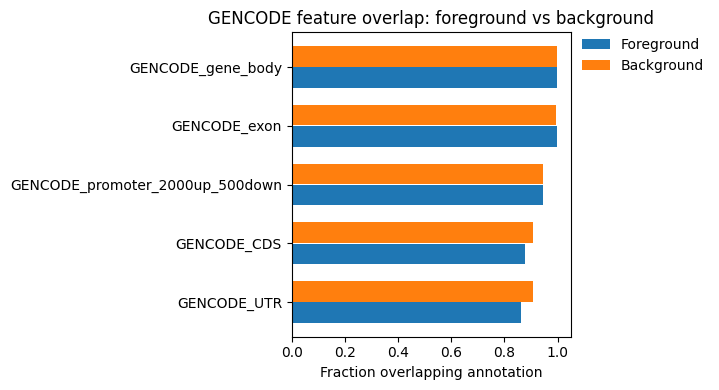

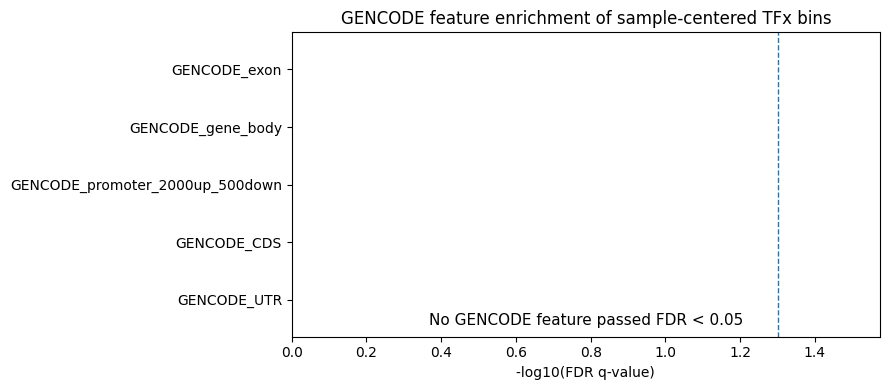

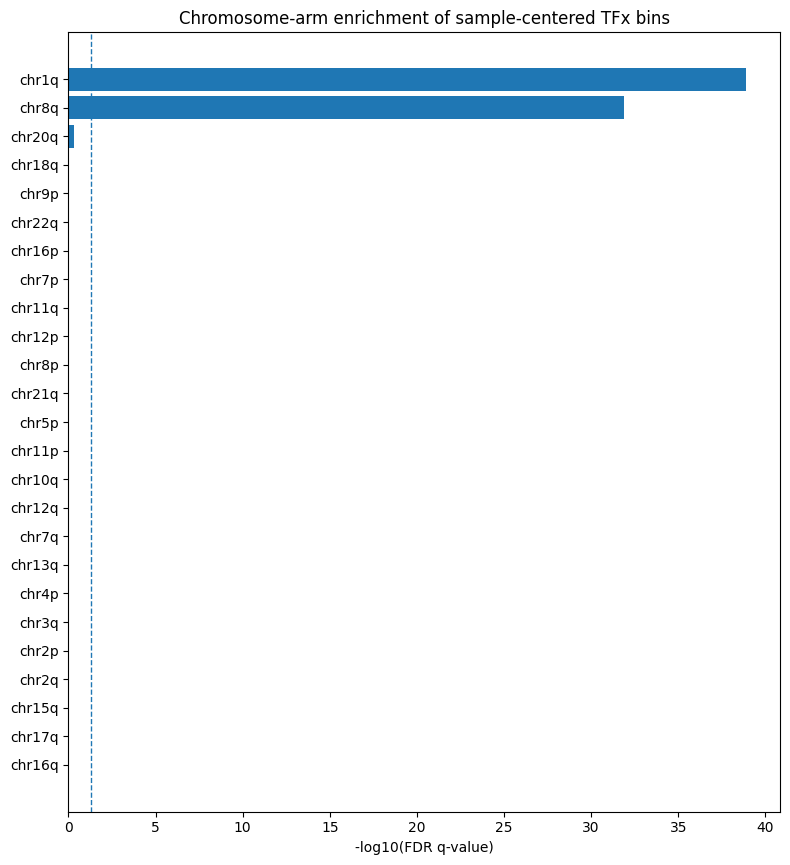

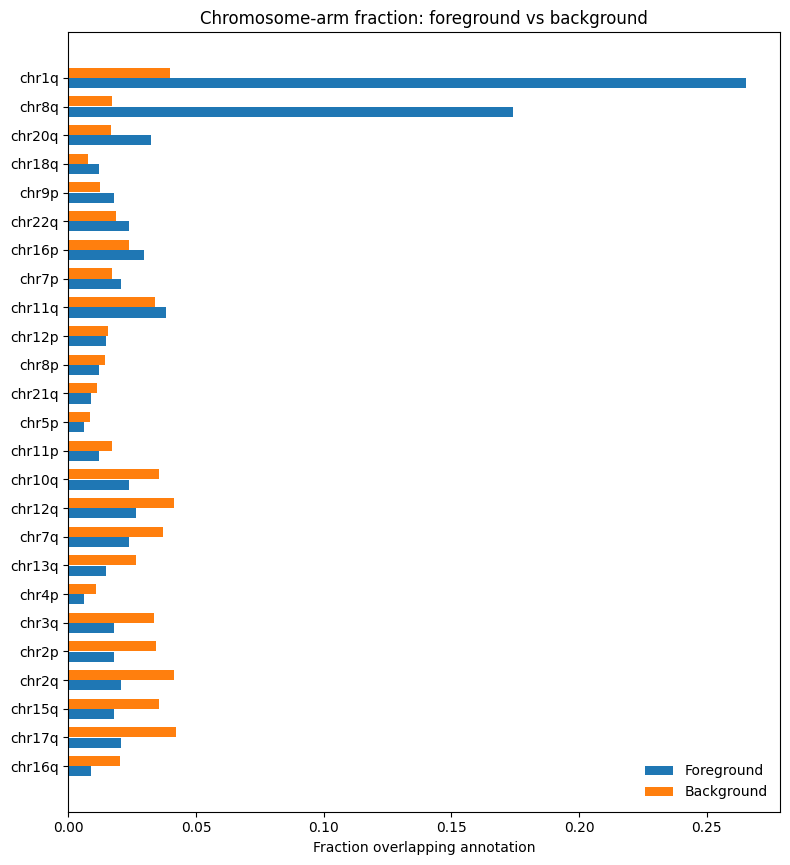

Top cytoband enrichments with chromosome labels:


,foreground,category_type,category,foreground_total,foreground_count,foreground_fraction,background_total_excluding_foreground,background_count,background_fraction,odds_ratio,p_value,q_value
421,positive,cytoband_full,chr1q32.1,220,11,0.050000,4780,15,0.003138,16.719298,4.031584e-09,0.000002
422,positive,cytoband_full,chr8q22.2,220,7,0.031818,4780,4,0.000837,39.239437,8.252719e-08,0.000017
423,positive,cytoband_full,chr1q22,220,7,0.031818,4780,6,0.001255,26.148670,3.977640e-07,0.000056
424,positive,cytoband_full,chr8q21.3,220,5,0.022727,4780,1,0.000209,111.139535,9.131514e-07,0.000096
0,all,cytoband_full,chr1q32.1,339,11,0.032448,4661,15,0.003218,10.387398,3.638927e-07,0.000153
842,negative,cytoband_full,chr11q24.3,119,5,0.042017,4881,3,0.000615,71.315789,3.715087e-07,0.000156
425,positive,cytoband_full,chr8q24.13,220,7,0.031818,4780,10,0.002092,15.676056,3.873710e-06,0.000326
1,all,cytoband_full,chr8q22.2,339,7,0.020649,4661,4,0.000858,24.547440,1.613873e-06,0.000340
426,positive,cytoband_full,chr8q22.3,220,5,0.022727,4780,3,0.000628,37.031008,7.923096e-06,0.000556
427,positive,cytoband_full,chr8q24.3,220,7,0.031818,4780,12,0.002510,13.057903,9.304640e-06,0.000560


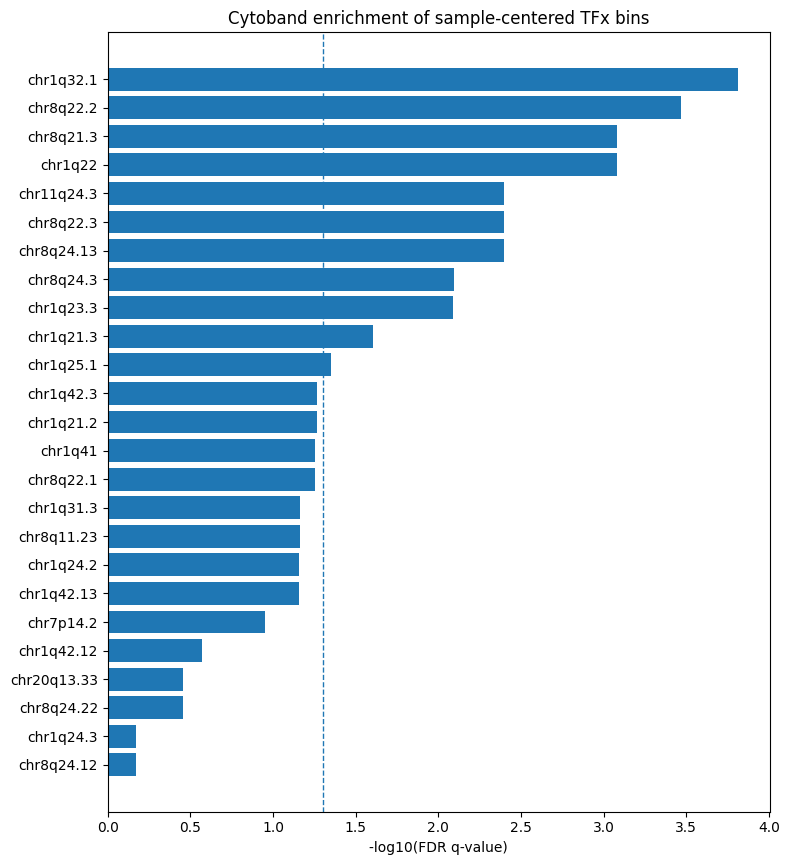

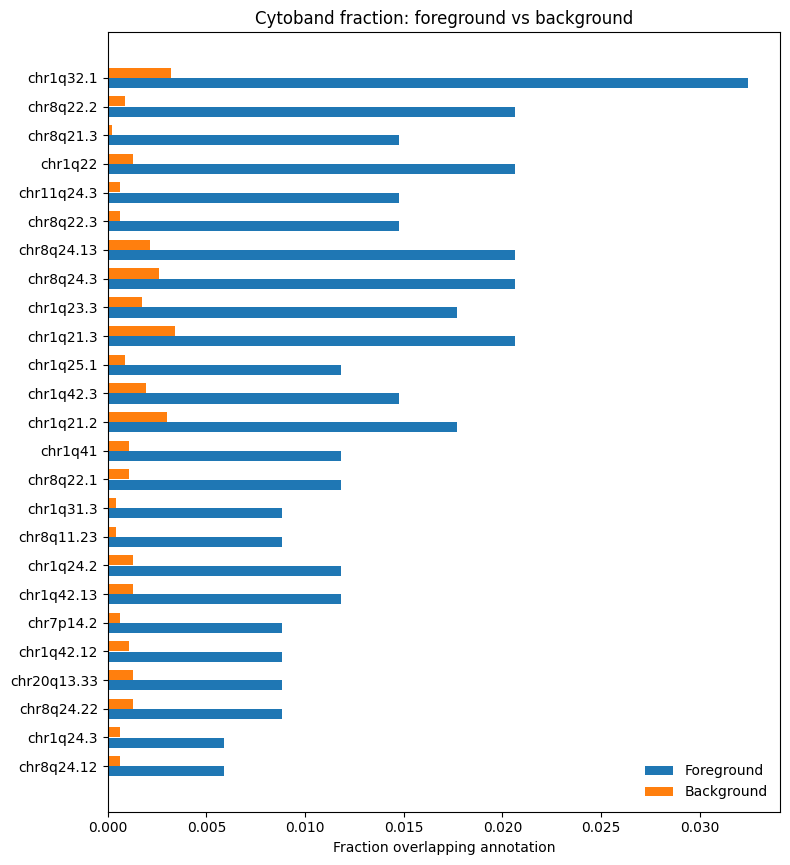

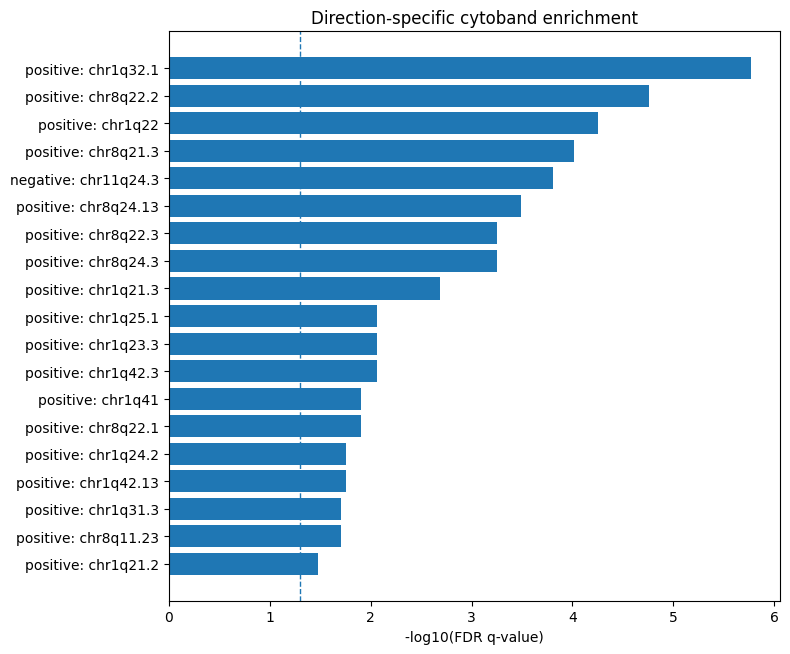

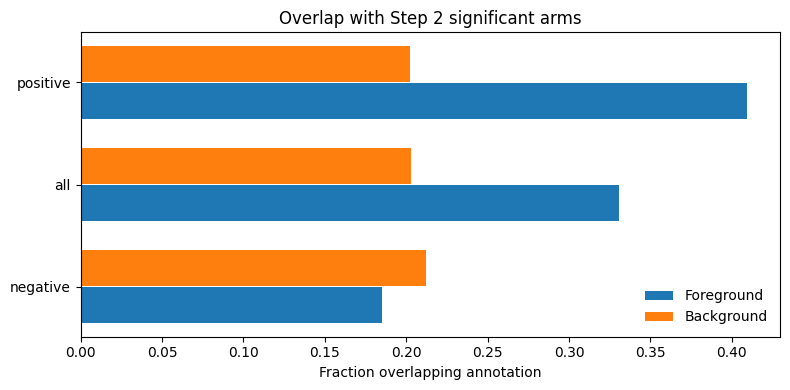

Plots saved to: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Fragmentation_analysis/Regional_Fragment_analysis/Result/Step5_enrichment_analysis_plots


In [12]:
# ============================================================
# STEP 7: Generate Step 5 enrichment plots
# ============================================================

# -------------------------
# GENCODE feature enrichment plots
# -------------------------

genomic_feature_all_for_plot = genomic_feature_enrichment[
    genomic_feature_enrichment["foreground"].eq("all")
].copy()


def plot_fraction_comparison_clean(
    df,
    path,
    title,
    label_col="annotation",
    top_n=25,
):
    """
    Cleaner foreground vs background fraction plot.
    Legend is moved outside so it does not overlap the bars.
    """

    if df.empty:
        print("No fraction comparison results to plot:", title)
        return

    tmp = df.copy()

    tmp = tmp.sort_values(
        ["foreground_fraction", "background_fraction"],
        ascending=[False, False]
    ).head(top_n)

    tmp = tmp.iloc[::-1].copy()
    y = np.arange(tmp.shape[0])

    fig, ax = plt.subplots(figsize=(9, max(4, 0.45 * tmp.shape[0])))

    ax.barh(
        y - 0.18,
        tmp["foreground_fraction"],
        height=0.35,
        label="Foreground"
    )

    ax.barh(
        y + 0.18,
        tmp["background_fraction"],
        height=0.35,
        label="Background"
    )

    ax.set_yticks(y)
    ax.set_yticklabels(tmp[label_col].astype(str))
    ax.set_xlabel("Fraction overlapping annotation")
    ax.set_ylabel("")
    ax.set_title(title)

    max_x = max(
        tmp["foreground_fraction"].max(),
        tmp["background_fraction"].max()
    )

    ax.set_xlim(0, min(1.05, max_x * 1.15))

    ax.legend(
        frameon=False,
        loc="upper left",
        bbox_to_anchor=(1.02, 1.0),
        borderaxespad=0
    )

    fig.tight_layout(rect=[0, 0, 0.82, 1])
    fig.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()


def plot_enrichment_bar_clean(
    df,
    path,
    title,
    label_col="annotation",
    top_n=25,
    fdr_alpha=0.05,
):
    """
    Cleaner -log10(FDR q-value) plot.
    If no feature is enriched, it prints this clearly on the plot.
    """

    if df.empty:
        print("No enrichment results to plot:", title)
        return

    tmp = df.copy()
    tmp = tmp[tmp["q_value"].notna()].copy()

    if tmp.empty:
        print("No valid q-values to plot:", title)
        return

    tmp["minus_log10_q"] = -np.log10(
        np.clip(tmp["q_value"].astype(float), 1e-300, 1.0)
    )

    tmp = tmp.sort_values(
        ["q_value", "odds_ratio"],
        ascending=[True, False]
    ).head(top_n)

    tmp = tmp.iloc[::-1].copy()

    threshold = -np.log10(fdr_alpha)
    max_x = max(tmp["minus_log10_q"].max(), threshold * 1.1, 0.1)

    fig, ax = plt.subplots(figsize=(9, max(4, 0.45 * tmp.shape[0])))

    ax.barh(
        tmp[label_col].astype(str),
        tmp["minus_log10_q"]
    )

    ax.axvline(
        threshold,
        linewidth=1,
        linestyle="--"
    )

    ax.set_xlim(0, max_x * 1.1)
    ax.set_xlabel("-log10(FDR q-value)")
    ax.set_ylabel("")
    ax.set_title(title)

    if tmp["q_value"].min() >= fdr_alpha:
        ax.text(
            0.5,
            0.03,
            "No GENCODE feature passed FDR < 0.05",
            transform=ax.transAxes,
            ha="center",
            va="bottom",
            fontsize=11
        )

    fig.tight_layout()
    fig.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()


# overlap fraction
# This shows how many bins overlap each GENCODE annotation.
plot_fraction_comparison_clean(
    genomic_feature_all_for_plot,
    path=STEP5_PLOT_DIR / "05_gencode_feature_overlap_fraction_comparison_all_bins.png",
    title="GENCODE feature overlap: foreground vs background",
    label_col="annotation",
    top_n=TOP_N_PLOT,
)

# enrichment significance
# This shows whether overlap is higher than expected compared with background.
plot_enrichment_bar_clean(
    genomic_feature_all_for_plot,
    path=STEP5_PLOT_DIR / "05_gencode_feature_enrichment_barplot_all_bins.png",
    title="GENCODE feature enrichment of sample-centered TFx bins",
    label_col="annotation",
    top_n=TOP_N_PLOT,
    fdr_alpha=FDR_ALPHA,
)
# -------------------------
# Chromosome arm enrichment plots
# -------------------------

arm_all_for_plot = arm_enrichment[
    arm_enrichment["foreground"].eq("all")
].copy()

plot_enrichment_bar(
    arm_all_for_plot,
    path=STEP5_PLOT_DIR / "05_chromosome_arm_enrichment_barplot_all_bins.png",
    title="Chromosome-arm enrichment of sample-centered TFx bins",
    label_col="category",
    top_n=TOP_N_PLOT,
)

plot_fraction_comparison(
    arm_all_for_plot,
    path=STEP5_PLOT_DIR / "05_chromosome_arm_overlap_fraction_comparison_all_bins.png",
    title="Chromosome-arm fraction: foreground vs background",
    label_col="category",
    top_n=TOP_N_PLOT,
)

# -------------------------
# Cytoband enrichment plots
# -------------------------

def make_full_cytoband_label(df):
    out = df.copy()

    out["cytoband_full"] = np.where(
        out["cytoband"].notna() & out["chrom"].notna(),
        out["chrom"].astype(str) + out["cytoband"].astype(str),
        np.nan
    )

    return out


primary_cb = make_full_cytoband_label(primary)
positive_cb = make_full_cytoband_label(positive)
negative_cb = make_full_cytoband_label(negative)
background_cb = make_full_cytoband_label(background)

# Re-run cytoband enrichment using full cytoband labels
cytoband_full_enrichment_all = category_enrichment(
    primary_cb,
    background_cb,
    "cytoband_full",
    "all",
    MIN_BACKGROUND_COUNT_FOR_ENRICHMENT
)

cytoband_full_enrichment_pos = category_enrichment(
    positive_cb,
    background_cb,
    "cytoband_full",
    "positive",
    MIN_BACKGROUND_COUNT_FOR_ENRICHMENT
)

cytoband_full_enrichment_neg = category_enrichment(
    negative_cb,
    background_cb,
    "cytoband_full",
    "negative",
    MIN_BACKGROUND_COUNT_FOR_ENRICHMENT
)

cytoband_full_enrichment = pd.concat(
    [
        cytoband_full_enrichment_all,
        cytoband_full_enrichment_pos,
        cytoband_full_enrichment_neg,
    ],
    ignore_index=True
)

# Save cytoband table
cytoband_full_enrichment.to_csv(
    STEP5_TABLE_DIR / "05_cytoband_full_label_enrichment_results.tsv",
    sep="\t",
    index=False
)

print("Top cytoband enrichments with chromosome labels:")
display(
    cytoband_full_enrichment
    .sort_values(["q_value", "odds_ratio"], ascending=[True, False])
    .head(30)
)

# Plot cytoband enrichment for all significant bins
cyto_full_all_for_plot = cytoband_full_enrichment[
    cytoband_full_enrichment["foreground"].eq("all")
].copy()

plot_enrichment_bar(
    cyto_full_all_for_plot,
    path=STEP5_PLOT_DIR / "05_cytoband_full_label_enrichment_barplot_all_bins.png",
    title="Cytoband enrichment of sample-centered TFx bins",
    label_col="category",
    top_n=TOP_N_PLOT,
)

plot_fraction_comparison(
    cyto_full_all_for_plot,
    path=STEP5_PLOT_DIR / "05_cytoband_full_label_fraction_comparison_all_bins.png",
    title="Cytoband fraction: foreground vs background",
    label_col="category",
    top_n=TOP_N_PLOT,
)

# Optional: direction-specific cytoband enrichment plot
cyto_full_direction_for_plot = cytoband_full_enrichment[
    cytoband_full_enrichment["foreground"].isin(["positive", "negative"])
].copy()

cyto_full_direction_sig = cyto_full_direction_for_plot[
    cyto_full_direction_for_plot["q_value"].lt(FDR_ALPHA)
].copy()

if cyto_full_direction_sig.empty:
    print("No FDR-significant direction-specific cytoband enrichments to plot.")
else:
    cyto_full_direction_sig["label"] = (
        cyto_full_direction_sig["foreground"].astype(str)
        + ": "
        + cyto_full_direction_sig["category"].astype(str)
    )

    plot_enrichment_bar(
        cyto_full_direction_sig,
        path=STEP5_PLOT_DIR / "05_cytoband_full_label_direction_specific_barplot.png",
        title="Direction-specific cytoband enrichment",
        label_col="label",
        top_n=TOP_N_PLOT,
    )

# -------------------------
# Step 2 significant arm enrichment
# -------------------------

plot_fraction_comparison(
    step2_arm_enrichment,
    path=STEP5_PLOT_DIR / "05_step2_significant_arm_overlap_fraction.png",
    title="Overlap with Step 2 significant arms",
    label_col="foreground",
    top_n=3,
)

# -------------------------
# Custom BED enrichment plots if available
# -------------------------

if "custom_bed_enrichment" in globals() and not custom_bed_enrichment.empty:
    plot_enrichment_bar(
        custom_bed_enrichment[
            custom_bed_enrichment["foreground"].eq("all")
        ],
        path=STEP5_PLOT_DIR / "05_custom_BED_enrichment_barplot_all_bins.png",
        title="Custom BED enrichment of sample-centered TFx bins",
        label_col="annotation",
        top_n=TOP_N_PLOT,
    )

print("Plots saved to:", STEP5_PLOT_DIR)

Direction-specific GENCODE feature enrichment:


,foreground,annotation,foreground_total,foreground_overlap,foreground_fraction,background_total_excluding_foreground,background_overlap,background_fraction,odds_ratio,p_value,q_value
10,positive,GENCODE_CDS,220,208,0.945455,4780,4317,0.903138,1.859007,0.018685,0.28027
1,positive,GENCODE_gene_body,220,220,1.000000,4780,4765,0.996862,inf,0.508684,1.00000
7,positive,GENCODE_exon,220,220,1.000000,4780,4760,0.995816,inf,0.405879,1.00000
13,positive,GENCODE_UTR,220,203,0.922727,4780,4324,0.904603,1.259292,0.220947,1.00000
5,negative,GENCODE_promoter_2000up_500down,119,113,0.949580,4881,4608,0.944069,1.115777,0.500587,1.00000
4,positive,GENCODE_promoter_2000up_500down,220,207,0.940909,4780,4514,0.944351,0.938312,0.656371,1.00000
8,negative,GENCODE_exon,119,118,0.991597,4881,4862,0.996107,0.461127,0.919213,1.00000
2,negative,GENCODE_gene_body,119,118,0.991597,4881,4867,0.997132,0.339429,0.951810,1.00000
11,negative,GENCODE_CDS,119,89,0.747899,4881,4436,0.908830,0.297603,1.000000,1.00000
14,negative,GENCODE_UTR,119,89,0.747899,4881,4438,0.909240,0.296132,1.000000,1.00000



Direction-specific chromosome-arm enrichment:


,foreground,category_type,category,foreground_total,foreground_count,foreground_fraction,background_total_excluding_foreground,background_count,background_fraction,odds_ratio,p_value,q_value
39,positive,chrom_arm,chr1q,220,88,0.400000,4780,187,0.039121,16.374332,3.061404e-57,1.193948e-55
40,positive,chrom_arm,chr8q,220,58,0.263636,4780,81,0.016946,20.769852,3.631926e-44,7.082256e-43
41,positive,chrom_arm,chr20q,220,11,0.050000,4780,78,0.016318,3.172740,1.644183e-03,2.137437e-02
78,negative,chrom_arm,chr9p,119,5,0.042017,4881,58,0.011883,3.647157,1.644468e-02,3.244202e-01
80,negative,chrom_arm,chr22q,119,6,0.050420,4881,89,0.018234,2.858904,2.495540e-02,3.244202e-01
79,negative,chrom_arm,chr11q,119,9,0.075630,4881,162,0.033190,2.383333,1.997426e-02,3.244202e-01
81,negative,chrom_arm,chr8p,119,4,0.033613,4881,66,0.013522,2.537549,8.443083e-02,8.232006e-01
82,negative,chrom_arm,chr21q,119,3,0.025210,4881,53,0.010858,2.355888,1.476790e-01,8.314627e-01
89,negative,chrom_arm,chr5p,119,2,0.016807,4881,40,0.008195,2.068803,2.640342e-01,8.314627e-01
83,negative,chrom_arm,chr7p,119,4,0.033613,4881,83,0.017005,2.010686,1.521502e-01,8.314627e-01



Direction-specific cytoband enrichment:


,foreground,category_type,category,foreground_total,foreground_count,foreground_fraction,background_total_excluding_foreground,background_count,background_fraction,odds_ratio,p_value,q_value
203,positive,cytoband,q32.1,220,11,0.050000,4780,29,0.006067,8.622505,6.981849e-07,0.000142
204,positive,cytoband,q22,220,9,0.040909,4780,28,0.005858,7.238998,2.222795e-05,0.002256
205,positive,cytoband,q24.13,220,7,0.031818,4780,17,0.003556,9.207677,5.290856e-05,0.002822
206,positive,cytoband,q21.3,220,13,0.059091,4780,70,0.014644,4.225673,5.561275e-05,0.002822
207,positive,cytoband,q42.3,220,5,0.022727,4780,9,0.001883,12.328165,2.277584e-04,0.009247
208,positive,cytoband,q41,220,4,0.018182,4780,5,0.001046,17.685185,3.859824e-04,0.013059
209,positive,cytoband,q42.13,220,4,0.018182,4780,6,0.001255,14.734568,6.212041e-04,0.018015
211,positive,cytoband,q42.12,220,3,0.013636,4780,5,0.001046,13.202765,3.992715e-03,0.090058
210,positive,cytoband,q24.3,220,9,0.040909,4780,62,0.012971,3.245834,3.620236e-03,0.090058
212,positive,cytoband,q23.3,220,9,0.040909,4780,69,0.014435,2.912219,6.795766e-03,0.137954


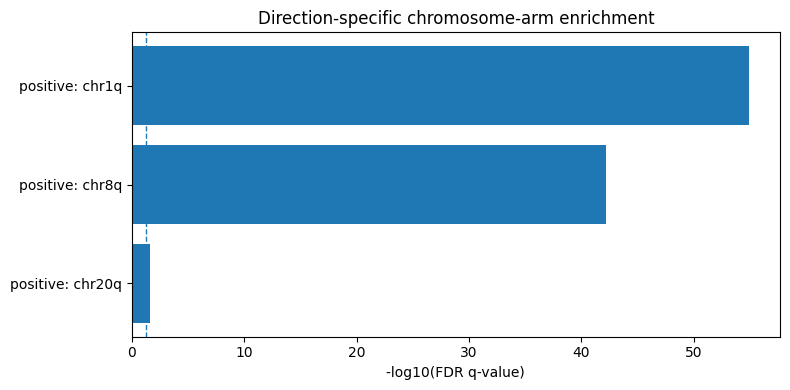

In [9]:

# ============================================================
# STEP 8: Direction-specific enrichment summary
# ============================================================

# Combine key direction-specific results.
direction_feature = genomic_feature_enrichment[
    genomic_feature_enrichment["foreground"].isin(["positive", "negative"])
].copy()

direction_arm = arm_enrichment[
    arm_enrichment["foreground"].isin(["positive", "negative"])
].copy()

direction_cytoband = cytoband_enrichment[
    cytoband_enrichment["foreground"].isin(["positive", "negative"])
].copy()

direction_feature.to_csv(
    STEP5_TABLE_DIR / "05_direction_specific_gencode_feature_enrichment.tsv",
    sep="\t",
    index=False,
)

direction_arm.to_csv(
    STEP5_TABLE_DIR / "05_direction_specific_chromosome_arm_enrichment.tsv",
    sep="\t",
    index=False,
)

direction_cytoband.to_csv(
    STEP5_TABLE_DIR / "05_direction_specific_cytoband_enrichment.tsv",
    sep="\t",
    index=False,
)

print("Direction-specific GENCODE feature enrichment:")
display(direction_feature.sort_values(["q_value", "odds_ratio"], ascending=[True, False]).head(20))

print("\nDirection-specific chromosome-arm enrichment:")
display(direction_arm.sort_values(["q_value", "odds_ratio"], ascending=[True, False]).head(20))

print("\nDirection-specific cytoband enrichment:")
display(direction_cytoband.sort_values(["q_value", "odds_ratio"], ascending=[True, False]).head(20))

# Plot direction-specific arm enrichment, if any.
sig_direction_arm = direction_arm[direction_arm["q_value"].lt(FDR_ALPHA)].copy()

if sig_direction_arm.empty:
    print("No FDR-significant direction-specific arm enrichment to plot.")
else:
    sig_direction_arm["label"] = sig_direction_arm["foreground"].astype(str) + ": " + sig_direction_arm["category"].astype(str)
    plot_enrichment_bar(
        sig_direction_arm,
        path=STEP5_PLOT_DIR / "05_direction_specific_arm_enrichment_barplot.png",
        title="Direction-specific chromosome-arm enrichment",
        label_col="label",
        top_n=TOP_N_PLOT,
    )


In [10]:

# ============================================================
# STEP 9: Final Step 5 summary and scientific notes
# ============================================================

def count_sig(df):
    if df.empty or "q_value" not in df.columns:
        return 0
    return int(df["q_value"].lt(FDR_ALPHA).sum())

final_summary = pd.DataFrame([
    {"metric": "primary_foreground_bins", "value": primary.shape[0]},
    {"metric": "positive_TFx_bins", "value": positive.shape[0]},
    {"metric": "negative_TFx_bins", "value": negative.shape[0]},
    {"metric": "background_tested_bins", "value": background.shape[0]},
    {"metric": "FDR_significant_GENCODE_feature_enrichments", "value": count_sig(genomic_feature_enrichment)},
    {"metric": "FDR_significant_chromosome_arm_enrichments", "value": count_sig(arm_enrichment)},
    {"metric": "FDR_significant_cytoband_enrichments", "value": count_sig(cytoband_enrichment)},
    {"metric": "FDR_significant_custom_BED_enrichments", "value": count_sig(custom_bed_enrichment) if "custom_bed_enrichment" in globals() else 0},
])

final_summary.to_csv(
    STEP5_TABLE_DIR / "05_step5_final_summary.tsv",
    sep="\t",
    index=False,
)

display(final_summary)

notes = f"""
AURORA regional fragmentation Step 5 notes

Purpose:
Step 5 tests whether sample-centered tumor-fraction-associated regional fragmentation bins
are enriched in genomic or regulatory contexts.

Primary foreground:
Sample-centered FDR-significant tumor-fraction-associated bins from Step 4.
Number of foreground bins: {primary.shape[0]}

Direction-specific foregrounds:
Positive tumor-fraction coefficient bins: {positive.shape[0]}
Negative tumor-fraction coefficient bins: {negative.shape[0]}

Background:
Step 3 selected/tested sample-centered bins.
Number of background bins: {background.shape[0]}

Why this background is used:
The Step 3 bin-level screen tested a selected set of robust variable sample-centered bins.
Therefore, enrichment should be evaluated against the tested-bin universe rather than the whole genome.

Enrichment tests:
Fisher's exact test with foreground compared against background excluding foreground bins.
FDR correction was applied across annotations within each enrichment table.

GENCODE-derived annotations tested:
- gene bodies
- promoters ({PROMOTER_UPSTREAM_BP} bp upstream / {PROMOTER_DOWNSTREAM_BP} bp downstream of TSS)
- exons
- CDS
- UTRs

Additional analyses:
- chromosome-arm enrichment
- cytoband enrichment
- overlap/enrichment in Step 2 sample-centered significant arms
- direction-specific positive vs negative TFx bin enrichment

Important interpretation:
A significant enrichment means that sample-centered TFx-associated bins overlap a genomic feature
more often than expected from the Step 3 tested-bin background. It does not prove causality.
It supports prioritization of genomic/regulatory contexts for biological interpretation.

Main outputs:
Tables:
{STEP5_TABLE_DIR}

Plots:
{STEP5_PLOT_DIR}

BED files:
{STEP5_BED_DIR}
"""

notes_path = STEP5_TABLE_DIR / "05_step5_scientific_notes.txt"
with open(notes_path, "w") as fh:
    fh.write(notes.strip() + "\n")

print(notes)
print("Saved notes:", notes_path)
print("Step 5 notebook completed:", time.ctime())


,metric,value
0,primary_foreground_bins,339
1,positive_TFx_bins,220
2,negative_TFx_bins,119
3,background_tested_bins,5000
4,FDR_significant_GENCODE_feature_enrichments,0
5,FDR_significant_chromosome_arm_enrichments,5
6,FDR_significant_cytoband_enrichments,14
7,FDR_significant_custom_BED_enrichments,0



AURORA regional fragmentation Step 5 notes

Purpose:
Step 5 tests whether sample-centered tumor-fraction-associated regional fragmentation bins
are enriched in genomic or regulatory contexts.

Primary foreground:
Sample-centered FDR-significant tumor-fraction-associated bins from Step 4.
Number of foreground bins: 339

Direction-specific foregrounds:
Positive tumor-fraction coefficient bins: 220
Negative tumor-fraction coefficient bins: 119

Background:
Step 3 selected/tested sample-centered bins.
Number of background bins: 5000

Why this background is used:
The Step 3 bin-level screen tested a selected set of robust variable sample-centered bins.
Therefore, enrichment should be evaluated against the tested-bin universe rather than the whole genome.

Enrichment tests:
Fisher's exact test with foreground compared against background excluding foreground bins.
FDR correction was applied across annotations within each enrichment table.

GENCODE-derived annotations tested:
- gene bodies
- 